# Multiclass learning objectives: probabilities, gradients, and decisions

## 1. Introduction and learning objectives

The output layer is a statistical model, not just an activation added to a neural network. A categorical model normalizes mutually exclusive alternatives, a loss defines what distribution is rewarded, and a decision rule chooses an action. These choices are related but not interchangeable. Understanding their shapes, derivatives and information boundaries prepares the same learner to debug a small classifier and later a language model's token loss.

Derive stable log probabilities, softmax vector products and categorical gradients; implement linear and one-hidden-layer classifiers with manual NumPy backpropagation; and investigate label smoothing, observation weights, masking, temperature scaling and cost-sensitive decisions. Verify independent scalar objectives and hand cases before comparing training runs. Distinguish a correct derivative from successful optimization, a proper scoring rule from finite-sample calibration, and a learned representation from its class decisions.

**Prerequisites:** Stage 00 matrix calculus/probability/numerics, Stage 01 evaluation and the retained [backpropagation](backpropagation.ipynb) and [MLP](multilayer-perceptron.ipynb) chapters. Their binary targets/probabilities remain $(n,1)$. This chapter explicitly introduces integer class labels $(n,)$ and categorical target/probability arrays $(n,K)$. No earlier reference functions are imported. NumPy/Matplotlib are sufficient; no framework, data download or GPU is required.

## 2. Prerequisites and mathematical foundations

Observations are rows $X\in\mathbb R^{n\times d}$. A logit matrix $Z\in\mathbb R^{n\times K}$ contains real, unnormalized class scores. Its column order is a declared vocabulary, such as $(10,20,40)$; an integer label is not automatically a zero-based column index. A target distribution $Q\in\mathbb R^{n\times K}$ has nonnegative entries summing to one on each supervised row. Hard targets are one-hot; soft targets describe a distribution over mutually exclusive classes. For simultaneous independent binary labels, a different likelihood is needed—softmax forces its alternatives to share total mass one.

With temperature $T>0$, define
$$P_{ik}=\frac{e^{Z_{ik}/T}}{\sum_j e^{Z_{ij}/T}},\qquad
\log P_{ik}=\frac{Z_{ik}-m_i}{T}-\log\sum_j\exp\!\left(\frac{Z_{ij}-m_i}{T}\right),\quad m_i=\max_j Z_{ij}.$$
Subtract the maximum **before** dividing by temperature. This avoids overflowing a large irrelevant common logit offset. Log probabilities can remain representable when exponentiated probabilities round to zero. A finite log score should not be replaced by the log of a clipped probability. Extremely large differences or tiny temperatures can still exceed floating-point range; expose that failure.

Let nonnegative observation weights be $w_i$, with at least one positive, and $a_i=w_i/\sum_j w_j$. The data objective is **weighted mean categorical cross-entropy**
$$J_{data}=-\sum_{i\in A}a_i\sum_k Q_{ik}\log P_{ik},\qquad A=\{i:w_i>0\}.$$
It does not divide by $K$, and there is only one observation normalization. A zero weight masks a row; the reference uses an all-zero target placeholder there, permits an ignored integer label, and requires finite logits everywhere. An all-masked batch has no defined mean and is rejected. Replicating the entire batch with the same weights preserves the objective and network parameter gradient. Averaging separately within unequal-length sequences generally defines a different objective.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 04.04.01 — Specify the likelihood, columns, target, and decision

**Type:** Conceptual · **Answer:** Markdown

Explain the difference between logits, class probabilities, hard labels, soft target distributions, and chosen actions. Why must a declared class order be preserved? When is a categorical output inappropriate? State the target and weight convention needed to ignore a padded row without treating its placeholder as a true class.

**Expected outcome:** explicit mutually exclusive outcomes, $(n,)$ versus $(n,K)$ shapes, class-column alignment, and separate probability-estimation and decision assumptions.

**Your response to Exercise 04.04.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.01**

Three independent yes/no questions can all be true at once; three softmax alternatives cannot all have probability one. A placeholder has no supervision weight.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.01**

Logits are relative real scores, probabilities normalize those scores over a declared mutually exclusive vocabulary, and a hard label names one vocabulary element. Soft targets distribute target mass among those alternatives. An action can be the highest-probability class or a different cost-minimizing/reject action. Permuting probability columns without applying the same vocabulary/target permutation changes the statistical problem. Simultaneously true labels require a suitable multilabel likelihood rather than a categorical normalization. In this reference a masked row has weight zero and an all-zero target row; its integer placeholder may be outside the vocabulary, but active labels must be known. Every logit remains finite, so masking does not hide invalid model arithmetic. The retained binary network convention is unchanged.

</details>

## 3. Theoretical development and worked examples

### Jacobians, reverse products, curvature, and a redundant direction

For one row $p=\operatorname{softmax}(z/T)$,
$$\frac{\partial p_k}{\partial z_j}=\frac1T p_k(\delta_{kj}-p_j),\qquad
J_p=\frac1T[\operatorname{diag}(p)-pp^T].$$
For an upstream vector $v$, the reverse product is
$$J_p^T v=\frac1T p\odot\left(v-(p^Tv)\mathbf1\right).$$
It needs $O(K)$ work/storage per row, not an explicit $K\times K$ Jacobian. Adding any common scalar to a row's logits preserves all probabilities. Consequently $J_p\mathbf1=0$. Finite exact probabilities give rank $K-1$ when $K>1$; floating-point saturation can introduce additional numerical degeneracy.

Using $\sum_k Q_{ik}=1$ for active rows, differentiation of cross-entropy gives
$$G_{ik}=\frac{\partial J_{data}}{\partial Z_{ik}}=\frac{a_i}{T}(P_{ik}-Q_{ik}),\qquad G_i=0\text{ if }w_i=0.$$
The logit Hessian for one weighted row is $a_i[\operatorname{diag}(p)-pp^T]/T^2$. Its quadratic form is the weighted variance of the direction's entries under $p$, hence nonnegative, with a common-shift null direction. Convexity in logits does not make a multilayer network's parameter objective convex. A Hessian-vector product can use the same centered vector product without constructing dense blocks.

### Cross-entropy, KL, and changing the rewarded distribution

For fixed targets,
$$H(q,p)=H(q)+\mathrm{KL}(q\|p),\quad H(q)=-\sum_{q_k>0}q_k\log q_k.$$
The target-to-prediction KL direction matters. At a population conditional distribution $t$, ordinary categorical log loss is minimized by $p=t$, assuming that distribution is expressible and the expectations are well-defined. A correctly implemented loss does not make a finite fitted network calibrated or correctly specified.

Uniform label smoothing uses $q_\epsilon=(1-\epsilon)e_y+\epsilon u$, $u_k=1/K$, with $0\le\epsilon\le1$. It gives
$$H(q_\epsilon,p)=(1-\epsilon)H(e_y,p)+\epsilon H(u,p),\qquad H(u,p)=\mathrm{KL}(u\|p)+\log K.$$
It is not a penalty $\mathrm{KL}(p\|u)$ or simply the prediction entropy. Averaging over labels from $t$ changes the unconstrained optimum to $(1-\epsilon)t+\epsilon u$. For $0<\epsilon<1$, the training objective's minimum includes positive target entropy; compare models using a common **unsmoothed held-out NLL**, not their different smoothed training losses. Smoothing may help a finite procedure, but algebra alone supplies no universal accuracy/calibration improvement.

Class-dependent weights also change the target. If class $k$ receives positive weight $c_k$, minimizing conditional expected weighted log loss yields $p_k^*=c_k t_k/\sum_j c_jt_j$. A cost-sensitive decision using estimated unweighted $t$ is a different operation: choose action $a$ minimizing $\sum_k C_{ak}t_k$. Reweighting the likelihood is not a neutral way to keep the same probability interpretation.

### A rational hand case

For logits $(0,\log2,\log3)$ at $T=1$, probabilities are $(1/6,1/3,1/2)$. A hard target in the second column has NLL $\log3$ and gradient $(1/6,-2/3,1/2)$. The unscaled softmax Jacobian is
$$\begin{pmatrix}5/36&-1/18&-1/12\\-1/18&2/9&-1/6\\-1/12&-1/6&1/4\end{pmatrix}.$$
Every row/column sums to zero. At smoothing $.3$, the target becomes $(.1,.8,.1)$ and the NLL gradient becomes $(1/15,-7/15,2/5)$. Hard and soft target gradients share the same logit Hessian for fixed active weights. At $K=1$, the only probability is one and all categorical logit derivatives vanish.

### Manual network derivatives at one snapshot

A linear model has $Z=XW+b$, $W:(d,K),b:(K,)$. With penalty $\lambda\|W\|_F^2/2$ and no bias penalty,
$$\nabla_WJ=X^TG+\lambda W,\quad\nabla_bJ=\sum_iG_i,\quad\nabla_XJ=GW^T.$$
For one tanh hidden layer, $H=\tanh(XW_1+b_1)$, $Z=HW_2+b_2$, with widths $h$ and $K$. Penalize both weight matrices, not biases. Then
$$\nabla_{W_2}J=H^TG+\lambda W_2,\quad\nabla_{b_2}J=\sum_iG_i,$$
$$U=(GW_2^T)\odot(1-H^2),\quad\nabla_{W_1}J=X^TU+\lambda W_1,\quad\nabla_{b_1}J=\sum_iU_i,\quad\nabla_XJ=UW_1^T.$$
The output sensitivity already contains weight normalization and temperature. Do not divide downstream products or bias sums again. Compute every derivative using the same cached parameter snapshot before updating anything.

### Exercise 04.04.02 — Derive softmax products, categorical curvature, and smoothing

**Type:** Mathematical · **Answer:** Markdown

Derive the Jacobian and its vector product, the weighted categorical logit gradient/Hessian, and the entropy/KL identity. Prove the common-shift null direction and positive semidefiniteness in logits. Derive the population optima under uniform target smoothing and positive class weighting, and state why none of these proves global neural-network optimization or finite-sample calibration.

**Expected outcome:** correct $1/T$ versus $1/T^2$, one weight normalization, KL direction $q\|p$, and explicit distinctions between estimands and parameter optimization.

**Your response to Exercise 04.04.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.02**

Differentiate a normalized exponential; the denominator couples every output. The Hessian quadratic form is a variance under $p$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.02**

Differentiating $p_k$ gives $p_k(\delta_{kj}-p_j)/T$, so summing against $v_k$ gives the centered vector product. Differentiating negative target log probabilities gives $a_i(p-q)/T$ on active rows; another derivative gives $a_i(\operatorname{diag}(p)-pp^T)/T^2$. Its quadratic form is $a_i\operatorname{Var}_p(v_k)/T^2$, and the all-ones direction has zero variance. Expanding KL gives $H(q,p)-H(q)$. The smoothed population target is the expectation of $q_\epsilon$, namely $(1-\epsilon)t+\epsilon u$; positive class weights normalize $c\odot t$ instead. These are optima in a space of categorical distributions, not proofs of expressibility, successful finite optimization, correct sampling or calibration of a trained network. Hidden nonlinearities also destroy a general parameter-convexity claim.

</details>

### Exercise 04.04.03 — Audit probabilities, gradient coupling, and logits with large offsets

**Type:** Numerical · **Answer:** Markdown

Reproduce the hand probabilities, hard/smoothed gradients and Jacobian. Verify that a common offset of 1,000 preserves log probabilities without overflowing raw exponentials. Explain why the true class's derivative is negative while other classes' derivatives are positive, and what happens when all active target mass already equals the predicted distribution.

**Expected outcome:** normalized rational values, zero class-sum gradients, stable log scores and an appropriately restricted stationary-point interpretation.

**Your response to Exercise 04.04.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.03**

For an active target distribution, the entries of $p-q$ sum to zero. Zero data gradient at those logits does not remove an L2 parameter gradient.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.03**

Exponentials are proportional to $(1,2,3)$, so probabilities sum to one as $(1/6,1/3,1/2)$. Subtracting one in the true second column gives $(1/6,-2/3,1/2)$. Smoothing $.3$ gives target $(.1,.8,.1)$ and gradient $(1/15,-7/15,2/5)$. The displayed Jacobian has zero row/column sums and sends a common-shift direction to zero. Adding 1,000 cancels before exponentiation in the stable calculation, while a naive exponential overflows. With hard targets, reducing the true-class deficit and increasing other logit sensitivities describes a coupled competition, not independent binary outputs. If $p=q$, the data logit gradient is zero, but parameter regularization or another path can still contribute to the full objective.

</details>

## 4. Guided exercises

### Exercise 04.04.04 — Implement stable log softmax and reverse vector products

**Type:** Programming · **Answer:** Code

Implement bounded finite row checks, temperature validation, stable log probabilities and a softmax reverse product. Support empty query batches, $K=1$, common shifts, and exponentiated-probability underflow while keeping usable log scores. Reject unsupported shapes/ranges instead of clipping probabilities or constructing batch Jacobian tensors.

**Expected outcome:** independent scalar probability/log-score agreement and vector-product finite differences with $O(nK)$ storage.

In [ ]:
# Your code for Exercise 04.04.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.04**

Use shifted logits divided by temperature, then subtract a log normalizer. The reverse product centers its upstream vector by its probability-weighted row mean.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.04**

These local helpers cap rows at 2,000 and logits/features at 32 columns; they are inspectable teaching computations, not a large-vocabulary kernel. Finite logits are required even on rows later masked by a loss. Arithmetic overflow in differences or temperature scaling is visible. Underflow of negligible exponentials is permitted; at least one shifted exponential per row is one before normalization.

~~~python
def mc_rows(values, name='rows', empty=False, columns=32):
    x = np.asarray(values,dtype=float)
    if x.ndim != 2 or not 1 <= x.shape[1] <= columns or len(x) > 2000 or (not empty and len(x) == 0) or not np.isfinite(x).all():
        raise ValueError(name+' requires bounded finite row-wise arrays')
    return x

def mc_positive(value, name):
    a = np.asarray(value,dtype=float)
    if isinstance(value,(bool,np.bool_)) or a.ndim != 0 or not np.isfinite(a) or a <= 0:
        raise ValueError(name+' must be a finite positive scalar')
    return float(a)

def mc_log_probabilities(logits, temperature=1.):
    z = mc_rows(logits,'logits',empty=True); t = mc_positive(temperature,'temperature')
    with np.errstate(over='raise',invalid='raise',divide='raise',under='ignore'):
        shifted = (z-z.max(axis=1,keepdims=True))/t
        result = shifted-np.log(np.exp(shifted).sum(axis=1,keepdims=True))
    if not np.isfinite(result).all():
        raise FloatingPointError('log probabilities exceed arithmetic range')
    return result

def mc_softmax_vjp(logits, upstream, temperature=1.):
    z = mc_rows(logits,'logits',empty=True); v = mc_rows(upstream,'upstream',empty=True)
    if v.shape != z.shape:
        raise ValueError('upstream shape must match logits')
    t = mc_positive(temperature,'temperature'); p = np.exp(mc_log_probabilities(z,t))
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        result = p*(v-np.sum(p*v,axis=1,keepdims=True))/t
    if not np.isfinite(result).all():
        raise FloatingPointError('softmax vector product exceeded range')
    return result
~~~

</details>

### Exercise 04.04.05 — Build aligned targets, masks, and normalized observation weights

**Type:** Programming · **Answer:** Code

Implement an explicit integer vocabulary, class encoding, uniform smoothing and normalized nonnegative weights. Only active labels must belong to the vocabulary; inactive integer placeholders create zero target rows. Reject $(n,1)$ labels, unknown active classes, repeated vocabulary entries, all-masked batches and relative weights that disappear numerically. Do not silently treat class IDs as column numbers.

**Expected outcome:** aligned $(n,K)$ targets, inactive rows excluded, scale-invariant weight normalization and explicit label/shape failures.

In [ ]:
# Your code for Exercise 04.04.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.05**

Normalize large weights by their maximum before summing. A positive mathematical weight becoming numerical zero is a separate arithmetic limitation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.05**

This snippet depends on 04.04.04. It accepts arbitrary integer class IDs in the caller's supplied order. Weight masking is not a mechanism for hiding NaN labels or model computations: labels must still be an integer vector and logits remain finite. A masked integer may name no class, but a positive-weight unknown label fails. Target smoothing is applied only to active rows.

~~~python
def mc_vocabulary(classes):
    classes = np.asarray(classes)
    if classes.ndim != 1 or classes.dtype.kind not in 'iu' or not 1 <= len(classes) <= 32 or len(np.unique(classes)) != len(classes):
        raise ValueError('declare 1..32 distinct integer class IDs in column order')
    return classes.copy()

def mc_weights(n, weights=None):
    w = np.ones(n) if weights is None else np.asarray(weights,dtype=float)
    if w.shape != (n,) or not np.isfinite(w).all() or np.any(w < 0) or not np.any(w > 0):
        raise ValueError('finite nonnegative row weights with positive total required')
    with np.errstate(over='raise',invalid='raise',divide='raise',under='ignore'):
        scaled = w/w.max(); normalized = scaled/scaled.sum()
    if np.any((w > 0)&(normalized == 0)):
        raise FloatingPointError('positive relative weight vanished')
    return normalized,w > 0

def mc_targets(labels, classes, smoothing=0., weights=None):
    classes = mc_vocabulary(classes); labels = np.asarray(labels)
    if labels.ndim != 1 or labels.dtype.kind not in 'iu' or not 1 <= len(labels) <= 2000:
        raise ValueError('bounded integer labels require shape (n,), not (n,1)')
    epsilon = np.asarray(smoothing,dtype=float)
    if isinstance(smoothing,(bool,np.bool_)) or epsilon.ndim != 0 or not np.isfinite(epsilon) or not 0 <= epsilon <= 1:
        raise ValueError('smoothing must lie in [0,1]')
    _,active = mc_weights(len(labels),weights)
    equality = labels[:,None] == classes[None,:]
    if not np.all(equality[active].sum(axis=1) == 1):
        raise ValueError('an active label is outside the vocabulary')
    target = np.zeros((len(labels),len(classes)))
    target[active] = (1-float(epsilon))*equality[active]+float(epsilon)/len(classes)
    return target
~~~

</details>

### Exercise 04.04.06 — Implement the categorical objective, manual gradients, and curvature

**Type:** Programming · **Answer:** Code

Implement weighted mean CE, target entropy, target-to-prediction KL, logit gradient, log-temperature derivative and a logit Hessian-vector product. Require target mass one on active rows and exactly zero on inactive rows. Use zero-mass limits without $0\log0$ NaNs. Keep the log probabilities for NLL even when probabilities underflow.

**Expected outcome:** the hand values, CE = entropy + KL, independent finite differences in logits/log temperature, and a positive-semidefinite shift-invariant curvature check.

In [ ]:
# Your code for Exercise 04.04.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.06**

For log-temperature $\tau=\log T$, $\partial J/\partial\tau=\sum_i a_i\sum_k(Q_{ik}-P_{ik})(Z_{ik}-m_i)/T$. Using centered logits removes an irrelevant offset from the calculation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.06**

This snippet depends on 04.04.04–05. The Hessian product applies to valid fixed categorical targets on active rows; it is a logit-space data Hessian, not a full neural-network parameter Hessian. Entropy and KL are averaged with the same row weights as CE. No probability floor changes the estimator. Small numerical discrepancies in the identity are exposed by tolerance checks rather than repaired by forcing KL nonnegative.

~~~python
def mc_categorical_objective(logits, targets, weights=None, temperature=1.):
    z = mc_rows(logits,'logits'); q = mc_rows(targets,'targets')
    if q.shape != z.shape or np.any(q < 0):
        raise ValueError('nonnegative targets must match logits')
    normalized,active = mc_weights(len(z),weights)
    if not np.allclose(q[active].sum(axis=1),1.,atol=1e-12,rtol=0) or np.any(q[~active] != 0):
        raise ValueError('active target rows sum to one; inactive rows are zero')
    t = mc_positive(temperature,'temperature'); logp = mc_log_probabilities(z,t); p = np.exp(logp)
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        row_loss = -np.sum(q*logp,axis=1)
        target_log = np.zeros_like(q); positive = q > 0; target_log[positive] = np.log(q[positive])
        row_entropy = -np.sum(q*target_log,axis=1)
        kl = np.sum(q*(target_log-logp),axis=1)
        # Retain the computed target mass so roundoff in an admitted row sum
        # does not create a spurious common-shift derivative (notably at K=1).
        mass = q.sum(axis=1,keepdims=True)
        gradient = normalized[:,None]*(mass*p-q)/t
        centered = (z-z.max(axis=1,keepdims=True))/t
        log_temperature_gradient = float(np.sum(normalized[:,None]*(q-mass*p)*centered))
    result = dict(loss=float(normalized@row_loss),entropy=float(normalized@row_entropy),
        kl=float(normalized@kl),gradient=gradient,log_temperature_gradient=log_temperature_gradient,
        row_loss=row_loss,probability=p,log_probability=logp)
    if any(not np.isfinite(result[key]).all() for key in ('loss','entropy','kl','gradient','log_temperature_gradient')):
        raise FloatingPointError('categorical objective exceeded range')
    return result

def mc_logit_hvp(logits, direction, weights=None, temperature=1.):
    z = mc_rows(logits,'logits'); normalized,_ = mc_weights(len(z),weights)
    t = mc_positive(temperature,'temperature')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        result = normalized[:,None]*mc_softmax_vjp(z,direction,t)/t
    if not np.isfinite(result).all():
        raise FloatingPointError('logit curvature exceeded range')
    return result

hand_logits = np.array([[0.,np.log(2),np.log(3)]])
for epsilon in (0.,.3):
    q = mc_targets([20],[10,20,40],epsilon)
    result = mc_categorical_objective(hand_logits,q)
    print('hand smoothing/probability/CE/gradient',epsilon,result['probability'],result['loss'],result['gradient'])
~~~

</details>

### Exercise 04.04.07 — Backpropagate through linear and tanh classifiers manually

**Type:** Programming · **Answer:** Code

Implement explicit initialization, forward caches and all weight, bias and input gradients for both architectures. Use column widths $(d,K)$ or $(d,h),(h,K)$ with one-dimensional biases. Apply $\lambda\sum\|W\|^2/2$ to weight matrices only. Return derivatives before any update and preserve input/parameter arrays.

**Expected outcome:** independent finite differences for every parameter and input, correct weight/mask/temperature normalization, and no extra observation averaging in hidden layers.

In [ ]:
# Your code for Exercise 04.04.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.07**

The output sensitivity already includes the full data reduction. Cache tanh activations and use the same $W_2$ for every upstream derivative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.07**

This snippet depends on 04.04.04–06. Random fan-width initialization is a declared reproducible heuristic, not a universal guarantee against saturation. Width is capped at 64. The linear and MLP parameterizations have different capacity and compute even when they share an update count. Every derivative is taken at one snapshot; the training routine introduced later performs the updates separately.

~~~python
def mc_parameter_fields(parameters):
    if parameters['kind'] == 'linear':
        return ('W','b')
    if parameters['kind'] == 'mlp':
        return ('W1','b1','W2','b2')
    raise ValueError('unknown classifier kind')

def mc_initialize(kind, features, classes, seed=40401, width=24):
    if any(isinstance(v,(bool,np.bool_)) or not isinstance(v,(int,np.integer)) for v in (features,classes,width)) or not 1 <= features <= 32 or not 1 <= classes <= 32 or not 1 <= width <= 64:
        raise ValueError('bounded integer feature/class/hidden widths required')
    rng = np.random.default_rng(seed)
    if kind == 'linear':
        return dict(kind=kind,W=rng.normal(size=(features,classes))*np.sqrt(2/(features+classes)),b=np.zeros(classes))
    if kind == 'mlp':
        return dict(kind=kind,W1=rng.normal(size=(features,width))*np.sqrt(2/(features+width)),b1=np.zeros(width),
                    W2=rng.normal(size=(width,classes))*np.sqrt(2/(width+classes)),b2=np.zeros(classes))
    raise ValueError('kind must be linear or mlp')

def mc_forward(parameters, values):
    x = mc_rows(values,'features',empty=True)
    fields = mc_parameter_fields(parameters)
    if any(not np.isfinite(np.asarray(parameters[key])).all() for key in fields):
        raise ValueError('finite parameters required')
    with np.errstate(over='raise',invalid='raise'):
        if parameters['kind'] == 'linear':
            w,b = parameters['W'],parameters['b']
            if w.ndim != 2 or w.shape[0] != x.shape[1] or b.shape != (w.shape[1],) or not 1 <= w.shape[1] <= 32:
                raise ValueError('invalid linear parameter shapes')
            logits = x@w+b; hidden = None
        else:
            w1,b1,w2,b2 = (parameters[key] for key in fields)
            if w1.ndim != 2 or w2.ndim != 2 or w1.shape[0] != x.shape[1] or not 1 <= w1.shape[1] <= 64 or w2.shape[0] != w1.shape[1] or b1.shape != (w1.shape[1],) or b2.shape != (w2.shape[1],) or not 1 <= w2.shape[1] <= 32:
                raise ValueError('invalid MLP parameter shapes')
            preactivation = x@w1+b1
            if not np.isfinite(preactivation).all():
                raise FloatingPointError('hidden preactivation exceeded arithmetic range')
            hidden = np.tanh(preactivation); logits = hidden@w2+b2
    if not np.isfinite(logits).all():
        raise FloatingPointError('network forward arithmetic exceeded range')
    return logits,hidden

def mc_network_objective(parameters, values, targets, weights=None, penalty=0., temperature=1.):
    x = mc_rows(values,'features'); penalty = np.asarray(penalty,dtype=float)
    if penalty.ndim != 0 or not np.isfinite(penalty) or penalty < 0:
        raise ValueError('finite nonnegative L2 coefficient required')
    logits,hidden = mc_forward(parameters,x)
    categorical = mc_categorical_objective(logits,targets,weights,temperature)
    g = categorical['gradient']; gradients = {}
    with np.errstate(over='raise',invalid='raise'):
        if parameters['kind'] == 'linear':
            gradients['W'] = x.T@g+float(penalty)*parameters['W']; gradients['b'] = g.sum(axis=0)
            input_gradient = g@parameters['W'].T
        else:
            gradients['W2'] = hidden.T@g+float(penalty)*parameters['W2']; gradients['b2'] = g.sum(axis=0)
            upstream = (g@parameters['W2'].T)*(1-hidden**2)
            gradients['W1'] = x.T@upstream+float(penalty)*parameters['W1']; gradients['b1'] = upstream.sum(axis=0)
            input_gradient = upstream@parameters['W1'].T
        regularizer = 0. if float(penalty) == 0 else .5*float(penalty)*sum(float(np.sum(parameters[key]**2)) for key in gradients if key.startswith('W'))
        loss = categorical['loss']+regularizer
    if not np.isfinite(loss) or not np.isfinite(input_gradient).all() or any(not np.isfinite(value).all() for value in gradients.values()):
        raise FloatingPointError('network objective arithmetic exceeded range')
    return dict(loss=float(loss),data_loss=categorical['loss'],gradients=gradients,
                input_gradient=input_gradient,logits=logits,probability=categorical['probability'])
~~~

</details>

## 5. Implementation challenges

### Exercise 04.04.08 — Compare binary parameterizations and the L2 coefficient

**Type:** Mathematical · **Answer:** Markdown

Show that two logits give positive-class probability $\sigma((z_1-z_0)/T)$. For a scalar effective weight $w=w_1-w_0$, minimize $w_0^2+w_1^2$ over equivalent two-logit weights. Compare a two-logit penalty $\lambda(w_0^2+w_1^2)/2$ with a single-logit penalty $\lambda w^2/2$. Explain why equal probabilities need not mean equal regularized objectives at the same named lambda.

**Expected outcome:** a common-shift redundancy, minimum-norm weights $(-w/2,w/2)$ and a factor-of-two penalty distinction without changing the retained binary chapters.

**Your response to Exercise 04.04.08**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.08**

Write $w_1=w_0+w$ and minimize a quadratic in $w_0$. Biases are unpenalized in this chapter.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.08**

Dividing the two softmax exponentials by $e^{z_0/T}$ gives $p_1=1/(1+e^{-(z_1-z_0)/T})$. For fixed difference $w$, the squared norm is $w_0^2+(w_0+w)^2$, minimized at $w_0=-w/2,w_1=w/2$, with norm $w^2/2$. The two-logit penalty is therefore $\lambda w^2/4$, while a single-logit penalty with the same coefficient is $\lambda w^2/2$. To match those effective penalties, the two-logit lambda must be twice the single-logit lambda under these exact conventions. Bias common shifts remain unpenalized. Matching likelihoods does not justify ignoring parameterization, temperature or regularizer normalization when comparing implementations.

</details>

### Exercise 04.04.09 — Train with explicit budgets and training-only preprocessing

**Type:** Programming · **Answer:** Code

Implement a training-fitted coordinate transform and full-batch gradient descent for both architectures. Use 1,200 updates, step size .2, L2 coefficient .001 and width 24 in the standard experiment. Record the initial and every updated objective, final gradient norm, update count and whether a declared $10^{-3}$ diagnostic target was met. Do not silently stop early, expand budgets or call budget exhaustion convergence.

**Expected outcome:** a reproducible fixed-budget trace, parameters updated only after complete gradient calculation, and preprocessing that never sees held-out observations.

In [ ]:
# Your code for Exercise 04.04.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.09**

Carry the newly evaluated objective/gradients into the next update, so a step does not need two redundant gradient evaluations. The fixed budget is a controlled experiment, not a recommended optimizer for every network.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.09**

This snippet depends on 04.04.04–07. Training uses temperature one; temperature fitting is a later held-out operation. Each weight matrix receives the same explicitly defined penalty and biases remain unpenalized. The code reports a final gradient-norm target without using it to alter work. A finite step size does not guarantee monotone loss for arbitrary inputs; nonfinite arithmetic fails visibly. The shape and 3,000-step caps keep correctness experiments bounded.

~~~python
def mc_fit_scaler(train):
    x = mc_rows(train,'training features')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        mean = x.mean(axis=0); scale = np.sqrt(np.mean((x-mean)**2,axis=0))
    constant = np.all(x == x[0],axis=0)
    if np.any((scale <= 0)&~constant) or not np.isfinite(scale).all():
        raise FloatingPointError('nonconstant feature scale vanished')
    scale[constant] = 1.
    return dict(mean=mean.copy(),scale=scale.copy())

def mc_scale(values, scaler):
    x = mc_rows(values,'features',empty=True)
    if scaler['mean'].shape != (x.shape[1],) or scaler['scale'].shape != (x.shape[1],) or not np.isfinite(scaler['mean']).all() or not np.isfinite(scaler['scale']).all() or np.any(scaler['scale'] <= 0):
        raise ValueError('invalid training-fitted scaler')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        return (x-scaler['mean'])/scaler['scale']

def mc_train(kind, train, labels, classes, smoothing=0., seed=40401,
             steps=1200, learning_rate=.2, penalty=.001, width=24, weights=None):
    x = mc_rows(train,'training features'); classes = mc_vocabulary(classes)
    if isinstance(steps,(bool,np.bool_)) or not isinstance(steps,(int,np.integer)) or not 0 <= steps <= 3000:
        raise ValueError('use 0..3000 updates')
    rate = mc_positive(learning_rate,'learning rate')
    target = mc_targets(labels,classes,smoothing,weights)
    if len(target) != len(x):
        raise ValueError('training/target row counts differ')
    parameters = mc_initialize(kind,x.shape[1],len(classes),seed,width)
    evaluated = mc_network_objective(parameters,x,target,weights,penalty)
    trace = [evaluated['loss']]
    for _ in range(steps):
        # All sensitivities above belong to the same old parameter snapshot.
        parameters = dict(kind=kind,**{key:parameters[key]-rate*evaluated['gradients'][key]
                                      for key in mc_parameter_fields(parameters)})
        evaluated = mc_network_objective(parameters,x,target,weights,penalty)
        trace.append(evaluated['loss'])
    largest = max(float(np.max(np.abs(g))) for g in evaluated['gradients'].values())
    with np.errstate(over='raise',invalid='raise'):
        norm = 0. if largest == 0 else float(largest*np.sqrt(sum(float(np.sum((g/largest)**2)) for g in evaluated['gradients'].values())))
    return dict(parameters=parameters,loss_history=np.array(trace),iterations=int(steps),
                status='fixed_budget',gradient_norm=norm,gradient_target=1e-3,
                gradient_target_met=bool(norm <= 1e-3),smoothing=float(smoothing),seed=int(seed),
                learning_rate=rate,penalty=float(penalty),width=int(width))
~~~

</details>

### Exercise 04.04.10 — Audit every parameter and input against an independent scalar objective

**Type:** Programming · **Answer:** Code

Write a scalar-loop forward/loss oracle using scalar tanh and a separate log-sum-exp, not the network helpers. Central-difference every parameter and input at a fixed snapshot with nonuniform weights, a masked row, smoothing, L2 and nonunit temperature. Preserve the original arrays even if a probe raises. Report maximum absolute discrepancies with a declared tolerance.

**Expected outcome:** a checked derivative at one snapshot, including unpenalized biases and zero sensitivity for ignored input rows, without claiming that the optimizer or model is good.

In [ ]:
# Your code for Exercise 04.04.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.10**

Use small dimensions and nonsaturated parameters. The oracle should implement the loss definition independently, not call the analytic-gradient routine with gradients ignored.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.10**

This snippet depends on 04.04.04–07. The independent scalar oracle is deliberately limited to the tiny finite audit arrays; it is not the bounded vector kernel. It does not call the vector forward, softmax or weight-normalization helpers. Probe copies and a `finally` restoration prevent accidental drift between coordinates. Passing this check establishes only the declared local derivatives and loss convention.

~~~python
import copy
import math

def mc_scalar_loss(parameters, values, targets, weights, penalty, temperature):
    total = sum(float(w) for w in weights); loss = 0.
    for row,target,weight in zip(values,targets,weights):
        if weight == 0:
            continue
        if parameters['kind'] == 'linear':
            logits = [sum(float(row[j])*float(parameters['W'][j,k]) for j in range(len(row)))+float(parameters['b'][k]) for k in range(len(target))]
        else:
            hidden = [math.tanh(sum(float(row[j])*float(parameters['W1'][j,h]) for j in range(len(row)))+float(parameters['b1'][h])) for h in range(len(parameters['b1']))]
            logits = [sum(hidden[h]*float(parameters['W2'][h,k]) for h in range(len(hidden)))+float(parameters['b2'][k]) for k in range(len(target))]
        largest = max(logits); shifted = [(v-largest)/temperature for v in logits]
        log_normalizer = math.log(sum(math.exp(v) for v in shifted))
        loss += float(weight)*sum(float(q)*(log_normalizer-v) for q,v in zip(target,shifted))/total
    for key,value in parameters.items():
        if key.startswith('W'):
            loss += penalty*sum(float(v)**2 for v in value.ravel())/2
    return loss

def mc_gradient_audit(parameters, values, targets, weights, penalty=.07, temperature=.8, step=1e-5):
    parameters = copy.deepcopy(parameters); x = np.array(values,dtype=float,copy=True)
    analytic = mc_network_objective(parameters,x,targets,weights,penalty,temperature)
    errors = {}
    for key in mc_parameter_fields(parameters):
        numerical = np.empty_like(parameters[key])
        for index in np.ndindex(numerical.shape):
            original = parameters[key][index]
            try:
                parameters[key][index] = original+step
                plus = mc_scalar_loss(parameters,x,targets,weights,penalty,temperature)
                parameters[key][index] = original-step
                minus = mc_scalar_loss(parameters,x,targets,weights,penalty,temperature)
                numerical[index] = (plus-minus)/(2*step)
            finally:
                parameters[key][index] = original
        errors[key] = float(np.max(np.abs(numerical-analytic['gradients'][key])))
    numerical_x = np.empty_like(x)
    for index in np.ndindex(x.shape):
        original = x[index]
        try:
            x[index] = original+step; plus = mc_scalar_loss(parameters,x,targets,weights,penalty,temperature)
            x[index] = original-step; minus = mc_scalar_loss(parameters,x,targets,weights,penalty,temperature)
            numerical_x[index] = (plus-minus)/(2*step)
        finally:
            x[index] = original
    errors['inputs'] = float(np.max(np.abs(numerical_x-analytic['input_gradient'])))
    return dict(errors=errors,maximum=max(errors.values()),tolerance=1e-7,passed=bool(max(errors.values()) < 1e-7))

audit_x = np.array([[.2,-.4],[.5,.1],[-.3,.7]])
audit_weights = np.array([1.,2.,0.]); audit_targets = mc_targets([10,40,-1],[10,20,40],.15,audit_weights)
for kind in ('linear','mlp'):
    audit = mc_gradient_audit(mc_initialize(kind,2,3,40410,width=3),audit_x,audit_targets,audit_weights)
    print('independent parameter/input audit',kind,audit)
    assert audit['passed']
~~~

</details>

### Name the parameter when discussing calibration optimization

For fixed logits and targets, write inverse temperature $\beta=1/T$. The weighted NLL is $J(\beta)=\sum_i a_i[\log\sum_k e^{\beta Z_{ik}}-\beta\sum_kQ_{ik}Z_{ik}]$. Its second derivative is $\sum_i a_i\operatorname{Var}_{P_i}(Z_{ik})\ge0$, so it is convex in **inverse temperature**. A nonlinear change of coordinates need not preserve convexity. For $\tau=\log T$, $d^2J/d\tau^2=\beta J'(\beta)+\beta^2J''(\beta)$, which can be negative. A one-example correct binary prediction with logits $(0,1)$ at $\beta=.1$ is a finite counterexample. Also, convexity alone does not ensure a finite minimizer: entirely correctly ordered calibration labels can favor $T\to0$, and identical logits can make every temperature equivalent. The declared grid and derivative/boundary diagnostics keep these distinctions visible.

### Exercise 04.04.11 — Implement comparable metrics, temperature selection, and costs

**Type:** Programming · **Answer:** Code

Implement hard-target NLL, accuracy, multiclass Brier score summed over classes, and a ten-bin top-label ECE table with counts and empty bins. Fit a positive temperature using a declared finite grid on separate calibration rows, retaining every candidate's NLL and log-temperature derivative. Implement expected-cost decisions for an arbitrary nonnegative action-by-true-class matrix. Do not use probability clipping, final labels for temperature choice, or ECE as a calibration theorem.

**Expected outcome:** correct class alignment, explicit bin edges and metric reductions, first-minimum grid selection with a boundary diagnostic, and action decisions distinct from highest-probability labels.

In [ ]:
# Your code for Exercise 04.04.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.11**

Use $(\mathrm{lower},\mathrm{upper}]$ confidence bins, with zero included in the first bin. The prediction is the raw-logit argmax; positive temperature preserves its ordering in exact arithmetic even if rounded probabilities tie.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.11**

This snippet depends on 04.04.04–06. NLL always uses unsmoothed evaluation targets. Brier is an observation mean of the class-summed square error; dividing again by class count would be a different reported scale. ECE is a finite binned, top-label diagnostic with ten fixed equal-width bins, not full conditional calibration. Predictions use raw scores to avoid a rounding-induced argmax change at an extreme temperature. The grid minimum is not a stationary point or a proof of optimal temperature. Costs are a separate declared decision problem.

~~~python
def mc_metrics(logits, labels, classes, temperature=1., bins=10):
    z = mc_rows(logits,'evaluation logits'); classes = mc_vocabulary(classes)
    if z.shape[1] != len(classes) or isinstance(bins,(bool,np.bool_)) or not isinstance(bins,(int,np.integer)) or not 1 <= bins <= 50:
        raise ValueError('aligned class columns and 1..50 bins required')
    target = mc_targets(labels,classes); objective = mc_categorical_objective(z,target,temperature=temperature)
    prediction = z.argmax(axis=1); truth = target.argmax(axis=1); p = objective['probability']
    correct = prediction == truth; confidence = p[np.arange(len(z)),prediction]
    brier_rows = np.sum((p-target)**2,axis=1)
    edges = np.linspace(0.,1.,bins+1)
    assigned = np.maximum(0,np.searchsorted(edges,confidence,side='left')-1)
    table = []; ece = 0.
    for index in range(bins):
        mask = assigned == index; count = int(mask.sum())
        accuracy = float(correct[mask].mean()) if count else None
        mean_confidence = float(confidence[mask].mean()) if count else None
        if count:
            ece += count/len(z)*abs(accuracy-mean_confidence)
        table.append(dict(index=index,lower=float(edges[index]),upper=float(edges[index+1]),
                          count=count,accuracy=accuracy,confidence=mean_confidence))
    return dict(nll=objective['loss'],accuracy=float(correct.mean()),brier=float(brier_rows.mean()),ece=float(ece),
                bins=table,prediction=classes[prediction],row_nll=objective['row_loss'],
                row_brier=brier_rows,probability=p,log_probability=objective['log_probability'])

def mc_fit_temperature(logits, labels, classes, candidates=(.5,.75,1.,1.5,2.,3.)):
    z = mc_rows(logits,'calibration logits'); target = mc_targets(labels,classes)
    grid = np.asarray(candidates,dtype=float)
    if grid.ndim != 1 or not 1 <= len(grid) <= 16 or not np.isfinite(grid).all() or np.any(grid <= 0):
        raise ValueError('declare 1..16 finite positive temperatures')
    table = []
    for t in grid:
        objective = mc_categorical_objective(z,target,temperature=float(t))
        table.append(dict(temperature=float(t),nll=objective['loss'],log_temperature_gradient=objective['log_temperature_gradient']))
    chosen = int(np.argmin([row['nll'] for row in table]))
    return dict(temperature=table[chosen]['temperature'],chosen=chosen,table=table,
                status='grid_minimum',boundary=bool(chosen in (0,len(table)-1)))

def mc_cost_actions(probability, costs):
    p = mc_rows(probability,'probabilities',empty=True); c = np.asarray(costs,dtype=float)
    if np.any(p < 0) or not np.allclose(p.sum(axis=1),1.,atol=1e-12,rtol=0) or c.ndim != 2 or not 1 <= c.shape[0] <= 32 or c.shape[1] != p.shape[1] or not np.isfinite(c).all() or np.any(c < 0):
        raise ValueError('normalized probabilities and finite nonnegative action/class costs required')
    with np.errstate(over='raise',invalid='raise'):
        risks = p@c.T
    if not np.isfinite(risks).all():
        raise FloatingPointError('expected cost exceeds arithmetic range')
    return dict(action=risks.argmin(axis=1),expected_cost=risks)
~~~

</details>

## 6. Experiments and visualizations

The default illustration uses the analytic three-class slice $z=(s,0,0)$, not a completed general kernel or a trained learner implementation. Increasing one logit takes probability mass from the other two. In the second panel, smoothing changes the target and the loss being minimized; the different curves are not a direct comparison of model accuracy. A hard target's zero NLL is approached at an unbounded margin, whereas positive uniform smoothing has a finite optimum on this slice.

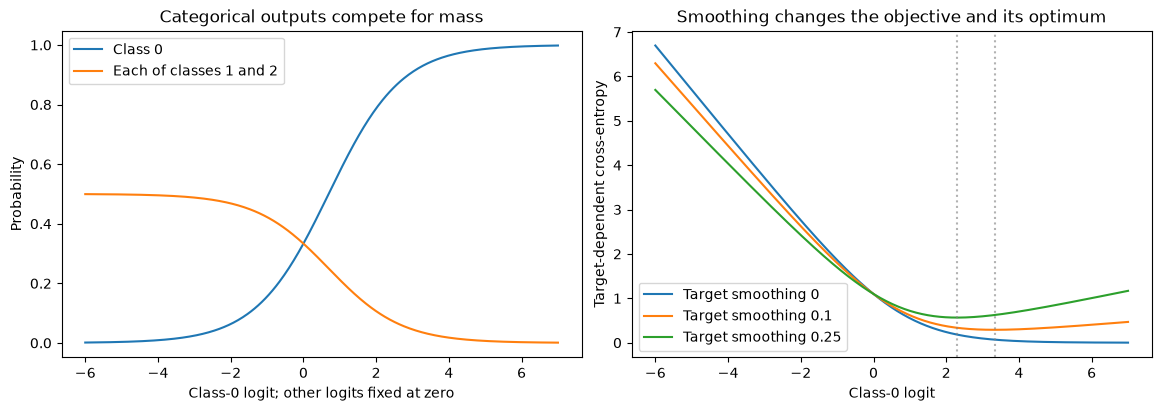

In [2]:
slice_score = np.linspace(-6.,7.,400)
denominator = np.exp(slice_score)+2
fig,axes = plt.subplots(1,2,figsize=(11.5,4.),layout='constrained')
axes[0].plot(slice_score,np.exp(slice_score)/denominator,label='Class 0')
axes[0].plot(slice_score,1/denominator,label='Each of classes 1 and 2')
axes[0].set(xlabel='Class-0 logit; other logits fixed at zero',ylabel='Probability',title='Categorical outputs compete for mass')
axes[0].legend()
for epsilon in (0.,.1,.25):
    target_mass = 1-epsilon+epsilon/3
    curve = np.log(denominator)-target_mass*slice_score
    axes[1].plot(slice_score,curve,label=f'Target smoothing {epsilon:g}')
    if epsilon:
        axes[1].axvline(np.log(3/epsilon-2),linestyle=':',color='grey',alpha=.6)
axes[1].set(xlabel='Class-0 logit',ylabel='Target-dependent cross-entropy',title='Smoothing changes the objective and its optimum')
axes[1].legend()
plt.show()

### Exercise 04.04.12 — Compare architectures and target smoothing with a fixed selection protocol

**Type:** Experimental · **Answer:** Code

Create independent training/validation/calibration/final samples from a declared three-ring categorical population. Fit preprocessing on 240 training rows only. Compare linear and width-24 tanh models, smoothing $0,.1,.25$, and three declared initialization seeds, using the same 1,200-step/.2-rate/.001-L2 budget. Select the first minimum **unsmoothed validation NLL** among all 18 fitted candidates on 120 rows; freeze that individual model, including its seed. Then fit its temperature on 199 separate calibration rows using the six declared temperatures. Preserve every trace, work/status record and temperature candidate; leave the 300 final rows untouched.

**Expected outcome:** a complete controlled comparison with real measured diagnostics, explicit seed-selection effort and no claim that equal steps mean equal compute or that seed ranges are risk confidence intervals.

In [ ]:
# Your code for Exercise 04.04.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.12**

Each smoothing value changes the training target. Comparing their training losses directly would mix estimands; validation uses the same hard-label NLL for every candidate.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.12**

This snippet depends on 04.04.04–11. Ring labels are sampled IID with equal class probabilities and vocabulary $(10,20,40)$. Angles are uniform and positive radii have class-dependent medians with log-normal variation. The nonlinear Bayes geometry is declared before training; no performance result is assumed. Each sample uses an independent child stream. The add-one frequency baseline is fit on training labels only and is explicitly a smoothed frequency estimator, not a clipping rule or a guarantee.

All 18 candidates see the same training/validation observations. Their seeds perturb initialization only, so spread across seeds is not uncertainty over new training/validation populations. The first validation minimum among all 18 includes seed selection in the protocol. Temperature fitting uses separate labels after that choice and supplies no conformal or subgroup-validity theorem. Fitting never touches final observations or uses their metrics to expand the grid.

~~~python
import time

def mc_ring_sample(rng, n):
    if isinstance(n,(bool,np.bool_)) or not isinstance(n,(int,np.integer)) or not 1 <= n <= 2000:
        raise ValueError('use 1..2000 generated observations')
    index = rng.integers(0,3,size=n); angle = rng.uniform(0.,2*np.pi,size=n)
    radius = np.array([.65,1.4,2.15])[index]*np.exp(.13*rng.normal(size=n))
    x = radius[:,None]*np.column_stack((np.cos(angle),np.sin(angle)))
    return dict(X=x,labels=np.array([10,20,40])[index])

def mc_prepare_experiment(steps=1200, seed=40400):
    streams = [np.random.default_rng(child) for child in np.random.SeedSequence(seed).spawn(4)]
    data = {name:mc_ring_sample(rng,n) for name,rng,n in zip(('train','validation','calibration','final'),streams,(240,120,199,300))}
    classes = np.array([10,20,40]); scaler = mc_fit_scaler(data['train']['X'])
    train = mc_scale(data['train']['X'],scaler); validation = mc_scale(data['validation']['X'],scaler)
    records = []; fitted = []
    for kind in ('linear','mlp'):
        for epsilon in (0.,.1,.25):
            for initialization_seed in (40401,40402,40403):
                start = time.perf_counter()
                model = mc_train(kind,train,data['train']['labels'],classes,epsilon,initialization_seed,steps)
                logits,_ = mc_forward(model['parameters'],validation)
                metrics = mc_metrics(logits,data['validation']['labels'],classes)
                records.append(dict(index=len(records),kind=kind,smoothing=epsilon,seed=initialization_seed,
                    validation_nll=metrics['nll'],validation_accuracy=metrics['accuracy'],
                    final_training_objective=float(model['loss_history'][-1]),gradient_norm=model['gradient_norm'],
                    gradient_target_met=model['gradient_target_met'],status=model['status'],iterations=model['iterations'],
                    fit_and_validation_seconds=time.perf_counter()-start))
                fitted.append(model)
    chosen = int(np.argmin([record['validation_nll'] for record in records]))
    calibration = mc_scale(data['calibration']['X'],scaler)
    calibration_logits,_ = mc_forward(fitted[chosen]['parameters'],calibration)
    temperature = mc_fit_temperature(calibration_logits,data['calibration']['labels'],classes)
    counts = mc_targets(data['train']['labels'],classes).sum(axis=0)
    frequency = (counts+1)/(len(train)+len(classes))
    return dict(data=data,classes=classes,scaler=scaler,fitted=fitted,records=records,chosen=chosen,
                temperature=temperature,frequency_baseline=frequency,calibration_logits=calibration_logits,
                seed=int(seed),final_used=False)

multiclass_study = mc_prepare_experiment()
for record in multiclass_study['records']:
    print(record)
print('frozen validation choice',multiclass_study['chosen'],multiclass_study['records'][multiclass_study['chosen']])
print('all calibration temperature candidates',multiclass_study['temperature'])
print('training-only frequency baseline',multiclass_study['frequency_baseline'])

fig,axes = plt.subplots(1,2,figsize=(11.8,4.2),layout='constrained')
for index,(record,model) in enumerate(zip(multiclass_study['records'],multiclass_study['fitted'])):
    if record['seed'] == 40401:
        axes[0].plot(model['loss_history'],label=f"{record['kind']} / smoothing {record['smoothing']:g}")
    condition = (0 if record['kind'] == 'linear' else 3)+[0.,.1,.25].index(record['smoothing'])
    jitter = (record['seed']-40402)*.07
    axes[1].scatter(condition+jitter,record['validation_nll'],s=32,
                    color='tab:orange' if index == multiclass_study['chosen'] else 'tab:blue')
axes[0].set(xlabel='Full-batch updates',ylabel='Training objective (different targets)',title='One declared seed per target/architecture')
axes[0].legend(fontsize=8)
axes[1].set(xticks=np.arange(6),xticklabels=['linear\n0','linear\n.1','linear\n.25','MLP\n0','MLP\n.1','MLP\n.25'],
            xlabel='Architecture and target smoothing',ylabel='Common unsmoothed validation NLL',title='All 18 candidates; orange is the frozen choice')
plt.show()
~~~

</details>

### Exercise 04.04.13 — Evaluate one frozen final panel and separate decisions from confidence

**Type:** Experimental · **Answer:** Code

Evaluate each frozen candidate once on final features, plus the training-only frequency baseline. Reuse the selected model's cached logits for raw versus temperature-scaled metrics and reliability diagrams. Report NLL, accuracy, Brier, all ECE bins and the paired calibrated-minus-raw NLL sensitivity from 400 row resamples. With a declared reject-action cost matrix, compare raw and scaled expected-cost actions. Do not replace the validation winner after final feedback. Reject a second final call on the same experiment bundle.

**Expected outcome:** complete actual final evidence, unchanged raw-logit class decisions under temperature, possible changes in cost actions, and correctly limited uncertainty/calibration claims.

In [ ]:
# Your code for Exercise 04.04.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.13**

Temperature changes probability values even while preserving class ordering. A confidence-sensitive reject action can therefore change without changing the highest-score class.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.13**

This snippet depends on 04.04.04–12. The in-memory guard consumes final access before inference, including if evaluation raises. It prevents accidental repetition in that bundle, not deliberate regeneration or cross-kernel reuse. Rerunning the whole study on the same final sample must be disclosed; the later capstone uses durable checkpoints. Analysis below reuses saved logits/losses and does not ask models to predict again.

Costs have rows for class actions 10, 20, 40 and a reject action; columns follow the true-class vocabulary. Missing true class 40 costs five, other wrong class actions cost one, and rejection costs .6. These values define the declared synthetic decision problem. The paired percentile range conditions on this fitted model, temperature and observed IID final rows; it excludes new fitting, selection, calibration, subgroup and shift variability.

~~~python
def mc_paired_sensitivity(differences, repeats=400, seed=40405):
    values = np.asarray(differences,dtype=float)
    if values.ndim != 1 or not 1 <= len(values) <= 2000 or not np.isfinite(values).all() or isinstance(repeats,(bool,np.bool_)) or not isinstance(repeats,(int,np.integer)) or not 1 <= repeats <= 800:
        raise ValueError('bounded finite differences and 1..800 resamples required')
    rng = np.random.default_rng(seed); means = np.empty(repeats)
    for index in range(repeats):
        means[index] = values[rng.integers(len(values),size=len(values))].mean()
    lower,upper = np.quantile(means,[.025,.975])
    return dict(mean=float(values.mean()),lower=float(lower),upper=float(upper),draws=means,repeats=int(repeats),seed=int(seed))

def mc_final_panel(study):
    if study['final_used']:
        raise RuntimeError('final access already used; analyze saved arrays')
    study['final_used'] = True
    final = study['data']['final']; x = mc_scale(final['X'],study['scaler']); classes = study['classes']
    logits = [mc_forward(model['parameters'],x)[0] for model in study['fitted']]
    metrics = [mc_metrics(z,final['labels'],classes) for z in logits]
    chosen = study['chosen']; raw = metrics[chosen]
    calibrated = mc_metrics(logits[chosen],final['labels'],classes,study['temperature']['temperature'])
    if not np.array_equal(raw['prediction'],calibrated['prediction']):
        raise ArithmeticError('positive temperature changed raw-score class decisions')
    baseline_logits = np.broadcast_to(np.log(study['frequency_baseline']),(len(x),len(classes)))
    baseline = mc_metrics(baseline_logits,final['labels'],classes)
    costs = np.array([[0.,1.,5.],[1.,0.,5.],[1.,1.,0.],[.6,.6,.6]])
    truth = mc_targets(final['labels'],classes).argmax(axis=1); actions = {}
    for name,evaluated in [('raw',raw),('temperature_scaled',calibrated)]:
        decision = mc_cost_actions(evaluated['probability'],costs)
        actions[name] = dict(actions=decision['action'],mean_realized_cost=float(costs[decision['action'],truth].mean()),
                             rejected=int(np.sum(decision['action'] == 3)))
    paired = mc_paired_sensitivity(calibrated['row_nll']-raw['row_nll'])
    result = dict(logits=np.array(logits),metrics=metrics,raw=raw,calibrated=calibrated,baseline=baseline,
                  paired=paired,costs=costs,actions=actions)
    study['final_result'] = result
    return result

multiclass_final = mc_final_panel(multiclass_study)
for record,metrics in zip(multiclass_study['records'],multiclass_final['metrics']):
    print('frozen final candidate',record['index'],record['kind'],record['smoothing'],record['seed'],
          {key:metrics[key] for key in ('nll','accuracy','brier','ece')})
for name in ('baseline','raw','calibrated'):
    print('final probability/decision metrics',name,{key:multiclass_final[name][key] for key in ('nll','accuracy','brier','ece')})
print('selected calibrated-minus-raw NLL conditional sensitivity',
      {key:value for key,value in multiclass_final['paired'].items() if key != 'draws'})
print('cost action summaries',{name:{key:value for key,value in row.items() if key != 'actions'}
                              for name,row in multiclass_final['actions'].items()})
try:
    mc_final_panel(multiclass_study)
except RuntimeError:
    print('second final call refused; use cached logits and metrics')
else:
    raise AssertionError('final guard failed')

fig,axes = plt.subplots(1,2,figsize=(11.4,4.1),layout='constrained')
for name,color in [('raw','tab:blue'),('calibrated','tab:orange')]:
    rows = [row for row in multiclass_final[name]['bins'] if row['count']]
    axes[0].plot([row['confidence'] for row in rows],[row['accuracy'] for row in rows],marker='o',label=name,color=color)
    axes[1].plot([row['index'] for row in rows],[row['count'] for row in rows],marker='o',label=name,color=color)
axes[0].plot([0.,1.],[0.,1.],linestyle=':',color='black')
axes[0].set(xlabel='Mean predicted top-class confidence',ylabel='Empirical top-class accuracy',
            title='Frozen final reliability bins (no validity guarantee)',xlim=(0.,1.),ylim=(0.,1.))
axes[0].legend()
axes[1].set(xlabel='Fixed confidence bin index',ylabel='Final rows in bin',title='Bin counts reveal sparse reliability evidence',xticks=np.arange(10))
axes[1].legend()
plt.show()

# A predeclared 40-by-40 probe grid and training rows illustrate geometry.
# They produce no additional final-sample inference or model-selection score.
axis = np.linspace(-3.,3.,40); horizontal,vertical = np.meshgrid(axis,axis)
probe = np.column_stack((horizontal.ravel(),vertical.ravel()))
probe_scaled = mc_scale(probe,multiclass_study['scaler'])
training = multiclass_study['data']['train']
training_index = mc_targets(training['labels'],multiclass_study['classes']).argmax(axis=1)
fig,axes = plt.subplots(1,2,figsize=(10.8,4.4),layout='constrained')
for ax,index,title in zip(axes,(0,multiclass_study['chosen']),('First declared unsmoothed linear fit','Validation-frozen selected fit')):
    grid_logits,_ = mc_forward(multiclass_study['fitted'][index]['parameters'],probe_scaled)
    prediction = grid_logits.argmax(axis=1).reshape(horizontal.shape)
    surface = ax.contourf(horizontal,vertical,prediction,levels=np.arange(4)-.5,cmap='viridis',alpha=.3)
    ax.scatter(*training['X'].T,c=training_index,cmap='viridis',vmin=-.5,vmax=2.5,s=10,alpha=.7,edgecolors='none')
    ax.set(xlabel='Original feature 1',ylabel='Original feature 2',title=title,xlim=(-3.,3.),ylim=(-3.,3.))
    ax.set_aspect('equal')
fig.suptitle('Geometry only: training rows and a fixed probe grid',fontsize=12)
colorbar = fig.colorbar(surface,ax=axes,ticks=[0,1,2],shrink=.8)
colorbar.set_ticklabels([str(value) for value in multiclass_study['classes']])
colorbar.set_label('Declared class ID')
plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### The next-token loss is a categorical loss with a declared unit

A future language-model batch may contain many token positions per sequence. Flatten valid supervised positions to rows, retain the declared vocabulary order, and decide how those rows are weighted. For sequences with lengths two and one, losses $(\log2,\log4)$ and $(\log8)$ have valid-token mean $2\log2$, but equal-sequence mean of means $2.25\log2$. They answer different weighting questions. A padded position contributes no supervised observation; a wrong denominator or a leaked padding class changes the objective and gradient scale.

Summing conditional next-token log probabilities uses the probability chain rule, not an assumption that tokens are independent; evaluation uncertainty must still respect dependence within sequences. If rows are valid autoregressive next-token predictions, perplexity for a specified tokenization is $\exp(\text{mean held-out token NLL})$. It is not exponentiated smoothed training loss or an arithmetic mean of sequence perplexities. Tokenization changes the counting unit, so raw per-token perplexities from different tokenizations need a common-unit interpretation before comparison. An image class probability and a language model's conditional next-token probability share categorical calculus, not identical data or evaluation semantics.

A loss mask removes a position's **direct logit-loss contribution**. It does not automatically remove every path through its input or a shared hidden value: another supervised prediction may depend on that context. Zero ignored-input derivatives in this chapter's row-independent classifiers rely on that architecture. In a later sequence model, loss masking and excluding a context position from the computation are separate choices. The existing shared-path chain rule still applies.

### Exercise 04.04.14 — Derive valid-token and equal-sequence reductions

**Type:** Mathematical · **Answer:** Markdown

For the two sequences above, derive both mean losses and their effective observation weights. Explain the padded-row convention and why an all-masked batch must not quietly return zero loss. Compute valid-token perplexity, exponentiated equal-sequence mean NLL and arithmetic mean of sequence perplexities, distinguishing the three quantities.

**Expected outcome:** valid-token weights $1/3$ each, equal-sequence weights $(1/4,1/4,1/2)$, losses $2\log2$ and $2.25\log2$, and an explicit evaluation unit.

**Your response to Exercise 04.04.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.14**

The two sequence mean losses are $1.5\log2$ and $3\log2$. Exponentiation does not commute with averaging.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.14**

Equal weighting of three valid positions gives $(1+2+3)\log2/3=2\log2$ and perplexity four. Equal weighting of two sequence means gives $(1.5+3)\log2/2=2.25\log2$, with exponential $2^{2.25}\approx4.75683$. The arithmetic mean of sequence perplexities is $(2^{1.5}+2^3)/2\approx5.41421$, a third quantity. A fourth padded row has weight zero and target mass zero; it does not enlarge the valid-token denominator. With no positive weights there is no defined mean supervised observation loss, so an explicit failure avoids fabricating evidence. Smoothed training targets and different vocabularies/tokenizations require their own interpretation, not a silent reuse of the same perplexity label.

</details>

### Exercise 04.04.15 — Audit masked positions and sequence weighting on a finite example

**Type:** Experimental · **Answer:** Code

Use four two-class logit rows with target probabilities $1/2,1/4,1/8$ for three valid class-0 targets and an ignored padding row. Compare valid-token and equal-sequence weighting, confirm zero padded-row derivatives, and check that batch replication preserves the objective and parameter reduction. Deliberately attempt an all-masked loss and record its rejection.

**Expected outcome:** the exact reductions above, a useful padding/denominator diagnostic and no dependence on an unfinished language-model implementation.

In [ ]:
# Your code for Exercise 04.04.15.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.15**

Use logits $(0,0),(0,\log3),(0,\log7)$ for the valid rows. The padded row's finite logits can be arbitrary.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.15**

This snippet depends on 04.04.04–06. It is a small categorical arithmetic check, not a trained language model or a dataset benchmark. An ignored integer is permitted only where its weight is zero. The weighted mean normalizes by positive supplied weight mass, so using reciprocal sequence lengths implements equal weighting of the two sequence means.

~~~python
masked_logits = np.array([[0.,0.],[0.,np.log(3)],[0.,np.log(7)],[1000.,-1000.]])
masked_labels = np.array([0,0,0,-1]); token_weights = np.array([1.,1.,1.,0.])
sequence_weights = np.array([.5,.5,1.,0.])
token_target = mc_targets(masked_labels,[0,1],weights=token_weights)
token_objective = mc_categorical_objective(masked_logits,token_target,token_weights)
sequence_objective = mc_categorical_objective(masked_logits,token_target,sequence_weights)
np.testing.assert_allclose(token_objective['loss'],2*np.log(2),atol=1e-14)
np.testing.assert_allclose(sequence_objective['loss'],2.25*np.log(2),atol=1e-14)
np.testing.assert_array_equal(token_objective['gradient'][-1],np.zeros(2))
replicated = mc_categorical_objective(np.tile(masked_logits,(2,1)),np.tile(token_target,(2,1)),np.tile(token_weights,2))
np.testing.assert_allclose(replicated['loss'],token_objective['loss'])
np.testing.assert_allclose(replicated['gradient'][:4]*2,token_objective['gradient'])
print('valid-token / equal-sequence NLL',token_objective['loss'],sequence_objective['loss'])
print('exponentials under the two declared units',np.exp(token_objective['loss']),np.exp(sequence_objective['loss']))
# A shared value h reaches two rows as (h,0) and (2*h,0).
# Only the second loss is active, but its path still differentiates h.
shared = mc_categorical_objective([[.3,0.],[.6,0.]],[[0.,0.],[0.,1.]],weights=[0.,1.])
shared_value_gradient = shared['gradient'][0,0]+2*shared['gradient'][1,0]
np.testing.assert_array_equal(shared['gradient'][0],np.zeros(2))
assert shared_value_gradient > 0
print('masked first logit row, nonzero shared-value derivative',shared_value_gradient)
try:
    mc_targets(masked_labels,[0,1],weights=np.zeros(4))
except ValueError:
    print('all-masked mean explicitly rejected')
else:
    raise AssertionError('undefined mean was accepted')
~~~

</details>

### Exercise 04.04.16 — Separate objective changes, metric limitations, and calibration claims

**Type:** Critical · **Answer:** Markdown

For a true conditional distribution $(.6,.3,.1)$, compute the unweighted and class-weighted optima with weights $(1,1,9)$. Explain why smoothing or reweighting is not a neutral probability-preserving operation. Construct a five-row example with predicted top-class confidence .8 and four correct predictions whose ECE is zero but whose known subgroups are miscalibrated. State what the temperature experiment actually establishes.

**Expected outcome:** a changed weighted optimum $(1/3,1/6,1/2)$, an ECE counterinterpretation and no unsupported subgroup, shift or correctness guarantee.

**Your response to Exercise 04.04.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.16**

Normalize the elementwise product of weights and true probabilities. Aggregate confidence/accuracy can hide opposite subgroup discrepancies.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.16**

Ordinary expected categorical loss rewards $(.6,.3,.1)$. Weighting gives $(.6,.3,.9)/1.8=(1/3,1/6,1/2)$, changing both the probability interpretation and the preferred class. Uniform target smoothing instead shrinks the target toward a declared reference distribution. Neither algebra guarantees better finite classification or calibration. For five identical forecasts $(.8,.2)$ predicting the first class, four first-class outcomes and one second-class outcome give overall confidence and accuracy .8, so their single occupied confidence bin has zero ECE up to rounding. A subgroup consisting of the four successes has accuracy one, and the remaining subgroup accuracy zero, although both receive .8. The temperature study only reports held-out metrics for a bounded selected procedure; fitting NLL and drawing a reliability diagram supplies no finite-sample conditional, subgroup, adaptive-stream or shift validity theorem.

</details>

### Bounded readings and source-to-code audits

| Primary source | Preparation and selected passage | Local reproduction and limits |
| --- | --- | --- |
| [Stanford CS231n linear classification notes](https://cs231n.github.io/linear-classify/), “Softmax classifier”, information-theory and numerical-stability passages; accessed October 25, 2026 | Matrix calculus and the categorical model | Translate column-vector weights to row-wise $(d,K)$ arrays and verify stable scores/derivatives. No coursework solution or image benchmark is reproduced. The live note gives no fixed revision date. |
| Szegedy et al., [Rethinking the Inception Architecture for Computer Vision](https://arxiv.org/pdf/1512.00567v3), v3 December 11, 2015, §7 on printed pp.6–7 | Cross-entropy, target distributions and KL direction | Reproduce uniform target smoothing and the CE decomposition, then derive the changed population target. This does not reproduce Inception or establish its reported benchmark gains for our small network. |
| Guo et al., [On Calibration of Modern Neural Networks](https://proceedings.mlr.press/v70/guo17a/guo17a.pdf), PMLR 70 (2017), §2 equations (2)–(3), §4.2 equation (9) | Separate held-out fitting/evaluation and probability metrics | Implement fixed-bin ECE and positive temperature scaling, retaining bin counts and all grid candidates. The grid is a local bounded approximation, not the paper's optimizer or full experiments; empirical effectiveness is not a universal guarantee. |

### Exercise 04.04.17 — Audit smoothing direction, normalization, and the temperature claim

**Type:** Critical · **Answer:** Markdown

Translate the selected source formulas into this chapter's array and loss conventions. Identify the KL direction induced by uniform smoothing, which source quantities are per-example versus averaged, and what positive temperature preserves. Name the coordinate in which fixed-logit NLL is convex. Explain why a finite-grid minimum and a small empirical ECE are weaker evidence than a proven global optimum or a statistical validity statement.

**Expected outcome:** an equation-to-code mapping with explicit source version, reductions, unsupported extrapolations and a bounded experimental claim.

**Your response to Exercise 04.04.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.17**

The smoothing penalty uses $H(u,p)$, and the temperature is shared across classes. A binned statistic and an optimization status are different kinds of evidence.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.17**

The source's per-example categorical loss becomes an observation-weighted mean here, with weights normalized once and row-wise logits. Uniform smoothing adds $\epsilon H(u,p)$, hence $\mathrm{KL}(u\|p)$ plus a constant, not the reverse KL. A common positive temperature divides every class logit and preserves their exact ordering, while changing probabilities and potentially cost-sensitive/reject actions. The convex parameter is inverse temperature; generic convexity in $T$ or $\log T$ does not follow. Our declared grid returns its first finite candidate minimum and reports boundary/derivative diagnostics; it need not be stationary or globally optimal. ECE summarizes top-label confidence bins under one finite sample and bin convention, hiding class/subgroup or sparse-bin structure. The local study checks the formulas and reports its own metrics; it does not inherit a paper's large-network results or promise calibration under another population or model version.

</details>

## 8. Review questions and knowledge checks

### Exercise 04.04.18 — Design independent edge-case and derivative oracles

**Type:** Numerical · **Answer:** Markdown

List independent scalar checks for log probabilities, Jacobian/VJP/Hessian products, log-temperature derivatives, every network parameter/input, the binary penalty mapping, weighted/masked reductions, class-column permutations, and metrics/costs. Include one class, empty query scoring, zero-mass targets, extreme common offsets, probability underflow, arithmetic overflow, zero weights, unknown active classes, confidence exactly on a bin edge and a rejected second final call.

**Expected outcome:** separated mathematical, numerical, shape/reduction and information-boundary checks that do not execute or grade learner answers.

**Your response to Exercise 04.04.18**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.18**

A target row's computed mass matters for exact numerical differentiation. An underflowed displayed probability need not imply an unusable log score.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.18**

Use scalar exponent/log-sum-exp and rational hand values; compare reverse products with central differences of a scalar dot product and Hessian products with an independent small Jacobian, including symmetry/PSD/null directions and temperature powers. Finite-difference separate scalar linear/tanh objectives with L2, biases, masks and nonuniform weights at one frozen snapshot. Check weight-scale and whole-batch replication invariance, zero input sensitivity for ignored rows, a consistent permutation of vocabulary/targets/columns and the two-logit minimum-norm regularizer. Compare confidence-bin counts and cost risks to explicit scalar tables, not another call to the same helper. At one class, probability is one and data derivatives vanish. At logits 1,000 apart, stable log scores can be finite while probabilities round to zero; distances beyond arithmetic range must fail. Reject all-masked/invalid active targets rather than returning fake means. Distinguish these implementation checks from empirical generalization, optimizer quality and calibration guarantees.

</details>

### Exercise 04.04.19 — Connect the objective to evolving AI without overextending it

**Type:** Critical · **Answer:** Markdown

Write a bounded follow-up for a later token classifier, decoder language model or learned embedding. Specify label/token conventions, masking and weighting unit, unsmoothed evaluation metric, preprocessing/data boundaries, objective changes, optimizer budget, independent derivatives and a final comparison. State what new evidence is needed before claiming reliability on a new model version or deployment population.

**Expected outcome:** a research-ready question linking categorical calculus to modern models while separating representation, training, prediction, calibration and decision evidence.

**Your response to Exercise 04.04.19**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 04.04.19**

Shared categorical math does not make class accuracy, token perplexity, generation quality and task utility interchangeable measures.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 04.04.19**

A later study could freeze a small decoder's vocabulary/data split, implement masked next-token mean NLL and verify all class/batch reductions on finite cases before training. Compare a declared objective change at matched data/work budgets, evaluate common unsmoothed held-out NLL in a specified tokenization, and separately assess generation/task behavior and resource use. A classifier or embedding study needs its own outcome semantics, information boundaries and decision costs. Reuse saved final scores for analysis and disclose adaptive test reuse. New model versions, data mixtures, tokenizers or deployment regimes can change every interpretation; additional independent evaluation, shift/dependence analysis and task-specific failure probes are needed. Correct softmax derivatives and a favorable small ECE alone do not establish that a language model's outputs are true or reliable for arbitrary decisions.

</details>

## 9. Summary and next learning steps

Categorical modeling starts with mutually exclusive outcomes, explicit columns and a declared observation unit. Stable log probabilities support manual derivatives and meaningful loss values without probability clipping. Jacobian products expose output coupling and a common-shift null direction; the same reduction must flow through every network layer once. Smoothing, weights, masks, penalties and temperature each change a specific part of the objective or prediction and must be interpreted accordingly.

Before advancing, **explain** the likelihood, reductions, KL direction and decision rule; **implement** stable kernels and manual network gradients; **verify** independent scalar, shape, curvature, masking and metric cases; and **evaluate** all declared candidates while distinguishing fixed budgets, held-out selection, probability diagnostics and actual supported claims. The next planned Stage 04 unit introduces Momentum and Adam with explicit optimizer state and checkpoint behavior. Optimization geometry, normalization/dropout and a learner-built reverse-mode engine follow; advanced frameworks remain outside the current NumPy stage.